# 1: Raccolta ed Esplorazione Dati

Obiettivo: scaricare una serie storica di prezzi pulita e verificata.

**Nota sulla scelta dell'asset:** uso **SPY** (ETF che replica l'S&P 500).

(1) ha oltre 30 anni di storico molto liquido

(2) riflette il mercato ampio invece di un singolo titolo

(3) l'adjusted close incorpora dividendi/split, quindi i regimi riflettono davvero il comportamento del mercato e non artefatti tecnici.

Se preferissi l'indice puro senza il tracking error dell'ETF potrei usare ^GSPC, ma perderei l'adjusted close per i dividendi, per un HMM su regimi di mercato SPY resta la scelta più solida.

## Installazione pacchetti
Installo yfinance, pandas e matplotlib.

In [1]:
# Installazione delle librerie necessarie (silenziosa con -q)
!pip install -q yfinance pandas matplotlib


## Import
Importo le librerie che useremo.

In [2]:
# Import librerie
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Formattazione dei numeri nei DataFrame stampati: 5 decimali, perché rendimenti
# e volatilità giornalieri sono dell'ordine di 0.0001-0.01 e con 2 si leggerebbe 0.00
pd.set_option('display.float_format', lambda x: f'{x:,.5f}')


## Download dei dati storici
Scarico circa 9 anni di storico giornaliero per SPY.

In [3]:
# Parametri di download
TICKER = "SPY"
END_DATE = pd.Timestamp("2026-09-23")  # la data finale è fissata per mantenere costante il periodo storico analizzato, favorendo la riproducibilità dei risultati
START_DATE = END_DATE - pd.DateOffset(years=9)  # circa 9 anni di storico

raw_data = yf.download(
    TICKER,
    start=START_DATE.strftime('%Y-%m-%d'),
    end=END_DATE.strftime('%Y-%m-%d'),
    auto_adjust=False,   # vogliamo la colonna "Adj Close" esplicita, separata da "Close"
    progress=False
)

print(f"Righe scaricate: {len(raw_data)}")
raw_data.head()


Righe scaricate: 2260


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY,SPY
Date,,,,,,
2017-09-25,216.88673,248.92999,249.55000,248.08000,249.14999,57064400
2017-09-26,217.01744,249.08000,249.70000,248.81000,249.42000,54082000
2017-09-27,217.86256,250.05000,250.49001,248.87000,249.88000,81001400
2017-09-28,218.12398,250.35001,250.44000,249.63000,249.73000,44778800
2017-09-29,218.89067,251.23000,251.32001,250.13000,250.34000,85578000


## Isolare la colonna Adjusted Close
Teniamo solo il prezzo di chiusura aggiustato (dividendi/split inclusi) e scartiamo Open/High/Low/Volume.
Gestiamo anche il caso in cui yfinance restituisca colonne MultiIndex.

In [4]:
if isinstance(raw_data.columns, pd.MultiIndex):
    raw_data.columns = raw_data.columns.get_level_values(0)

# Selezioniamo solo l'adjusted close e lo rinominiamo
prices = raw_data[['Adj Close']].copy()
prices.rename(columns={'Adj Close': 'adj_close'}, inplace=True)
prices.index.name = 'date'

prices.head()


Price,adj_close
date,
2017-09-25,216.88673
2017-09-26,217.01744
2017-09-27,217.86256
2017-09-28,218.12398
2017-09-29,218.89067


## Controllo e gestione di valori mancanti / buchi
yfinance scarica solo i giorni in cui la borsa era aperta: weekend e festività USA non compaiono come NaN, semplicemente non ci sono righe per quei giorni.

Controlliamo comunque:

(1) NaN dentro la serie scaricata

(2) quanti giorni lavorativi (lun-ven) mancano rispetto a un calendario continuo, solo a scopo informativo (le festività di borsa ci rientrano, è atteso).

In [5]:
# 1) NaN nella serie scaricata
n_nan_before = int(prices['adj_close'].isna().sum())
print(f"Valori NaN trovati nella serie scaricata: {n_nan_before}")

# 2) Giorni lavorativi (Mon-Fri) assenti rispetto a un calendario continuo
full_bdays = pd.date_range(start=prices.index.min(), end=prices.index.max(), freq='B')
missing_bdays = full_bdays.difference(prices.index)
print(f"Giorni lavorativi assenti dalla serie (incluse festivita' di borsa): {len(missing_bdays)}")

# Gestione dei NaN, se presenti:
# - forward-fill: un prezzo mancante viene sostituito con l'ultimo prezzo valido precedente
#   ("nessun trading = prezzo invariato")
# - backward-fill di sicurezza SOLO per eventuali NaN residui a inizio serie
#   (dove non esiste un valore precedente da propagare in avanti)
if n_nan_before > 0:
    prices['adj_close'] = prices['adj_close'].ffill().bfill()
    n_nan_after = int(prices['adj_close'].isna().sum())
    print(f"NaN dopo forward-fill (+ backward-fill di sicurezza): {n_nan_after}")
else:
    n_nan_after = 0
    print("Nessun NaN da gestire: la serie scaricata e' gia' completa.")


Valori NaN trovati nella serie scaricata: 0
Giorni lavorativi assenti dalla serie (incluse festivita' di borsa): 87
Nessun NaN da gestire: la serie scaricata e' gia' completa.


## Plot del prezzo nel tempo
Grafico semplice per un controllo visivo: vogliamo vedere se la serie è "continua", senza salti anomali.

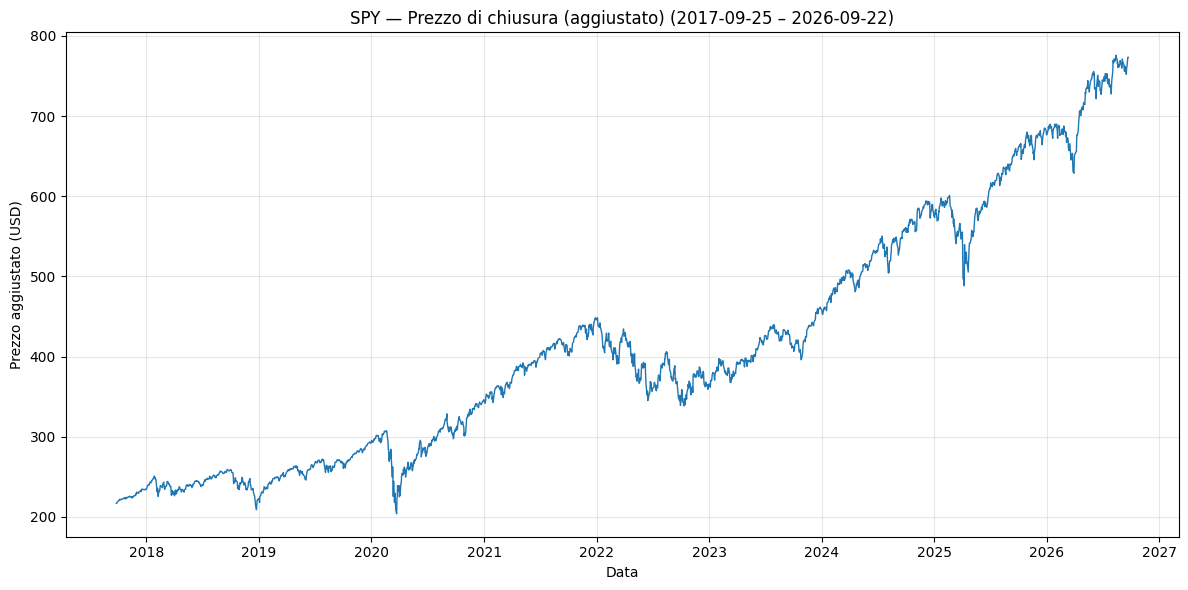

In [6]:
plt.figure(figsize=(12, 6))
plt.plot(prices.index, prices['adj_close'], linewidth=1)
plt.title(f"{TICKER} — Prezzo di chiusura (aggiustato) "
          f"({prices.index.min().date()} – {prices.index.max().date()})")
plt.xlabel("Data")
plt.ylabel("Prezzo aggiustato (USD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Riepilogo finale
Riepilogo: quante righe abbiamo, il range di date coperto, e cosa è successo con eventuali valori mancanti.

In [7]:
print("=" * 90)
print("SUMMARY: Dati", TICKER)
print("=" * 90)
print(f"Numero di righe (giorni di trading): {len(prices)}")
print(f"Range di date: {prices.index.min().date()} -> {prices.index.max().date()}")
print(f"NaN trovati nella serie originale: {n_nan_before}")
print(f"NaN dopo pulizia (ffill/bfill): {n_nan_after}")
print(f"Giorni lavorativi mancanti vs calendario continuo: {len(missing_bdays)} "
      f"(festivita' di borsa, atteso)")
print("-" * 90)


SUMMARY: Dati SPY
Numero di righe (giorni di trading): 2260
Range di date: 2017-09-25 -> 2026-09-22
NaN trovati nella serie originale: 0
NaN dopo pulizia (ffill/bfill): 0
Giorni lavorativi mancanti vs calendario continuo: 87 (festivita' di borsa, atteso)
------------------------------------------------------------------------------------------


# 2: Feature Engineering
Calcoliamo log return giornalieri e volatilità
rolling a 20 giorni, le feature che useremo per l'HMM.


In [8]:
import numpy as np


### Log return giornalieri
Perché log returns:

(1) additivi nel tempo (la somma di log return = log return cumulato)

(2) proprietà statistiche più stabili nel tempo rispetto al prezzo


In [9]:
# log_return_t = log(P_t) - log(P_t-1) = log(P_t / P_t-1)
prices['log_return'] = np.log(prices['adj_close'] / prices['adj_close'].shift(1))

prices[['adj_close', 'log_return']].head()


Price,adj_close,log_return
date,,
2017-09-25,216.88673,NaN
2017-09-26,217.01744,0.00060
2017-09-27,217.86256,0.00389
2017-09-28,218.12398,0.00120
2017-09-29,218.89067,0.00351


### Volatilità rolling (finestra 20 giorni)
Deviazione standard rolling dei log return su 20 giorni di trading (1 mese).


In [10]:
ROLLING_WINDOW = 20  # giorni di trading

prices['volatility_20d'] = prices['log_return'].rolling(window=ROLLING_WINDOW).std()

prices[['log_return', 'volatility_20d']].tail()


Price,log_return,volatility_20d
date,,
2026-09-16,-0.00442,0.00545
2026-09-17,0.01127,0.00606
2026-09-18,0.00129,0.00577
2026-09-21,0.01539,0.00667
2026-09-22,-0.00016,0.00662


### NaN introdotti dal calcolo rolling
1 NaN in log_return (primo giorno) e 20 in volatility_20d (finestra incompleta):
strutturali e attesi, li rimuoviamo con dropna mirato invece di riempirli.


In [11]:
n_nan_return = int(prices['log_return'].isna().sum())
n_nan_vol = int(prices['volatility_20d'].isna().sum())

print(f"NaN in log_return:     {n_nan_return}  (atteso: 1)")
print(f"NaN in volatility_20d: {n_nan_vol}  (atteso: {ROLLING_WINDOW })")

features = prices.dropna(subset=['log_return', 'volatility_20d']).copy()

print(f"\nRighe prima della pulizia: {len(prices)}")
print(f"Righe dopo la pulizia:    {len(features)}")
print(f"NaN residui in features:  {int(features[['log_return', 'volatility_20d']].isna().sum().sum())}")


NaN in log_return:     1  (atteso: 1)
NaN in volatility_20d: 20  (atteso: 20)

Righe prima della pulizia: 2260
Righe dopo la pulizia:    2240
NaN residui in features:  0


### Plot: prezzo, rendimenti e volatilità allineati nel tempo


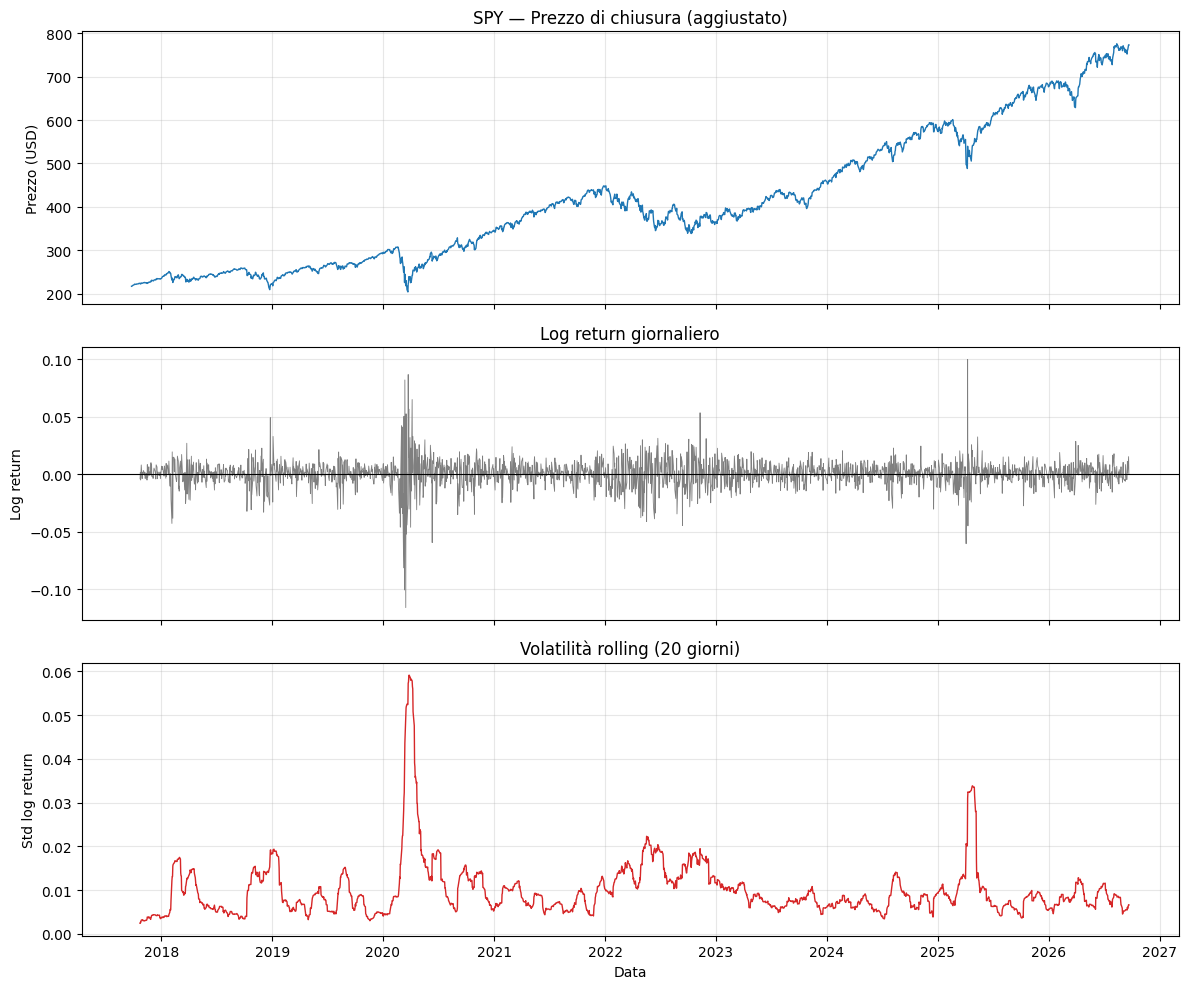

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(prices.index, prices['adj_close'], linewidth=1, color='tab:blue')
axes[0].set_title(f"{TICKER} — Prezzo di chiusura (aggiustato)")
axes[0].set_ylabel("Prezzo (USD)")
axes[0].grid(alpha=0.3)

axes[1].plot(features.index, features['log_return'], linewidth=0.6, color='tab:gray')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title("Log return giornaliero")
axes[1].set_ylabel("Log return")
axes[1].grid(alpha=0.3)

axes[2].plot(features.index, features['volatility_20d'], linewidth=1, color='tab:red')
axes[2].set_title(f"Volatilità rolling ({ROLLING_WINDOW} giorni)")
axes[2].set_ylabel("Std log return")
axes[2].set_xlabel("Data")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Riepilogo statistico finale


In [13]:
print("=" * 40)
print("SUMMARY: Feature Engineering")
print("=" * 40)
print(f"Righe finali (dopo pulizia NaN): {len(features)}")
print(f"Range di date: {features.index.min().date()} -> {features.index.max().date()}")
print("-" * 40)
print("Log return giornaliero:")
print(features['log_return'].describe()[['mean', 'std', 'min', 'max']])
print("-" * 40)
print(f"Volatilità rolling ({ROLLING_WINDOW}gg):")
print(features['volatility_20d'].describe()[['mean', 'std', 'min', 'max']])
print("-" * 40)


SUMMARY: Feature Engineering
Righe finali (dopo pulizia NaN): 2240
Range di date: 2017-10-23 -> 2026-09-22
----------------------------------------
Log return giornaliero:
mean    0.00055
std     0.01189
min    -0.11589
max     0.09986
Name: log_return, dtype: float64
----------------------------------------
Volatilità rolling (20gg):
mean   0.00995
std    0.00660
min    0.00241
max    0.05917
Name: volatility_20d, dtype: float64
----------------------------------------


# 3: Hidden Markov Model

Fittiamo un Gaussian HMM a 2 stati sulle feature (log return e volatilità rolling) per identificare i regimi di mercato.

Versione semplicistica: fit su tutta la storia in un colpo solo, il lookahead bias verrà rimosso nella successivamente(walk-forward).


In [14]:
# Installazione di hmmlearn
!pip install -q hmmlearn

# Import per l'HMM
from hmmlearn.hmm import GaussianHMM


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 9.9 MB/s eta 0:00:00


## Preparazione della matrice di feature
Costruisco la matrice di input per l'HMM usando rendimento log e volatilità rolling, e fisso il numero di stati nascosti a 2, per semplicità, senza assumere che sia il numero ottimale.

Le due feature vengono standardizzate (z-score) poichè hanno varianze molto piccole, dell'ordine di 1e-4 e 1e-5, senza standardizzazione la regolarizzazione di default delle covarianze di hmmlearn distorcerebbe le stime.

Qui media e deviazione standard sono calcolate su tutta la serie, cosa accettabile solo perché il fit (semplicistico) è già in-sample: nel walk-forward si useranno quelle del solo training.


In [15]:
# Numero di stati nascosti
N_STATES = 2

# Matrice di feature per l'HMM: rendimento log e volatilità rolling
X_raw = features[['log_return', 'volatility_20d']].values

# Standardizzazione (z-score) con media e std di TUTTA la serie: va bene solo
# per il fit naive, già in-sample. Nel walk-forward si usano quelle del training.
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)


## Fit del Gaussian HMM
Fitto l'HMM su tutta la serie storica in un colpo solo. Versione semplicistica con lookahead bias: verrà sistemata più avanti con un approccio walk-forward.


In [16]:
# Fit del Gaussian HMM
# covariance_type='full' per permettere di vedere la correlazione tra le due feature
# random_state fisso per riproducibilità
np.random.seed(42)
model = GaussianHMM(
    n_components=N_STATES,
    covariance_type='full',
    n_iter=1000,
    random_state=42
)
model.fit(X)

# Non usiamo monitor_.converged: in hmmlearn, a fit concluso, vale sempre True.
# Se viene raggiunto il limite massimo di iterazioni, occorre verificare ulteriormente la convergenza.
print(f"Iterazioni EM usate: {model.monitor_.iter} su 1000")
print(f"Log-likelihood finale: {model.score(X):.2f}")   # utile come diagnostica, non sufficiente da sola per confrontare modelli con diverse complessità
print("\nMatrice di transizione (persistenza degli stati):")
print(model.transmat_)


Iterazioni EM usate: 16 su 1000
Log-likelihood finale: -4279.63

Matrice di transizione (persistenza degli stati):
[[0.99084783 0.00915217]
 [0.01918171 0.98081829]]


## Estrazione della sequenza di stati
Estraggo, per ogni giorno, lo stato nascosto predetto dal modello.


In [17]:
# Sequenza di stati predetti, uno per ogni giorno
hidden_states = model.predict(X)
features['hmm_state'] = hidden_states
display(features[['adj_close', 'log_return', 'volatility_20d', 'hmm_state']].head(5))

print(f"\nPrimi valori con stato = 1:")
mask = features['hmm_state'] == 1
stati_1 = features[mask]
display(stati_1[['adj_close', 'log_return', 'volatility_20d', 'hmm_state']].head(5))



Price,adj_close,log_return,volatility_20d,hmm_state
date,,,,
2017-10-23,223.14246,-0.00390,0.00241,0
2017-10-24,223.53456,0.00176,0.00241,0
2017-10-25,222.42804,-0.00496,0.00273,0
2017-10-26,222.71556,0.00129,0.00273,0
2017-10-27,224.53651,0.00814,0.00312,0



Primi valori con stato = 1:


Price,adj_close,log_return,volatility_20d,hmm_state
date,,,,
2018-02-02,241.21974,-0.02201,0.00763,1
2018-02-05,231.13129,-0.04272,0.01221,1
2018-02-06,235.68506,0.01951,0.01309,1
2018-02-07,234.40651,-0.00544,0.01311,1
2018-02-08,225.61423,-0.03823,0.01550,1


## Visualizzazione: prezzo colorato per stato HMM
Plotto il prezzo aggiustato colorando lo sfondo in base allo stato predetto in quel giorno, per verificare a occhio se gli stati coincidono con periodi sensati (es. 2020, 2022).


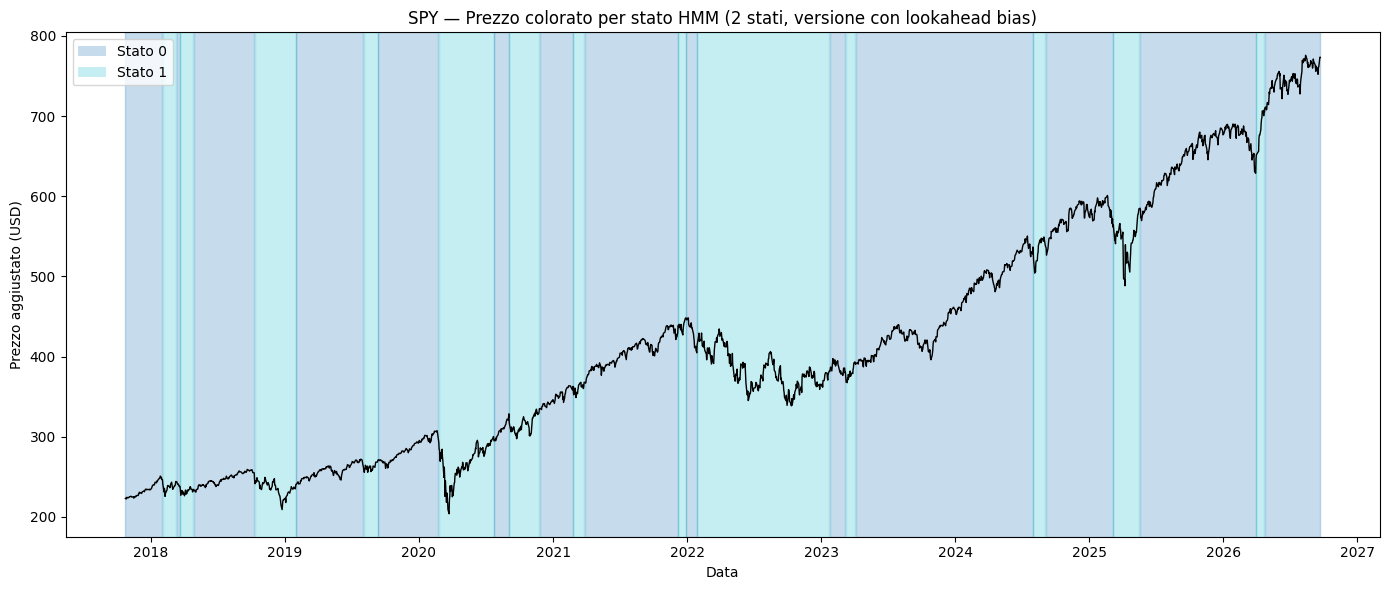

In [18]:
# Plot del prezzo con sfondo colorato in base allo stato HMM predetto
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(14, 6))
cmap = plt.get_cmap('tab10', N_STATES)

# Coloriamo lo sfondo per ogni tratto contiguo dello stesso stato
state_changes = features['hmm_state'].ne(features['hmm_state'].shift()).cumsum()
for _, segment in features.groupby(state_changes):
    state = segment['hmm_state'].iloc[0]
    ax.axvspan(segment.index[0], segment.index[-1], color=cmap(state), alpha=0.25)

ax.plot(features.index, features['adj_close'], color='black', linewidth=1)
ax.set_title(f"{TICKER} — Prezzo colorato per stato HMM "
             f"({N_STATES} stati, versione con lookahead bias)")
ax.set_xlabel("Data")
ax.set_ylabel("Prezzo aggiustato (USD)")

legend_elements = [Patch(facecolor=cmap(s), alpha=0.25, label=f"Stato {s}") for s in range(N_STATES)]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()


## Caratteristiche degli stati
Calcolo media e deviazione standard dei rendimenti, e volatilità media, per ciascuno stato, per assegnare un'etichetta intuitiva.

Le etichette numeriche 0/1 sono arbitrarie: è questa tabella a dire cosa rappresentano davvero.


In [19]:
# Caratteristiche di ciascuno stato, per assegnare un'etichetta intuitiva
print("=" * 100)
print(f"CARATTERISTICHE DEGLI STATI HMM ({N_STATES} stati, versione semplicistica)")
print("=" * 100)

state_stats = features.groupby('hmm_state').agg(
    n_giorni=('log_return', 'count'),
    return_medio=('log_return', 'mean'),
    return_std=('log_return', 'std'),
    volatilita_media=('volatility_20d', 'mean')
)

print(state_stats)
print("-" * 100)


CARATTERISTICHE DEGLI STATI HMM (2 stati, versione semplicistica)
           n_giorni  return_medio  return_std  volatilita_media
hmm_state                                                      
0              1527       0.00073     0.00710           0.00697
1               713       0.00017     0.01834           0.01635
----------------------------------------------------------------------------------------------------
